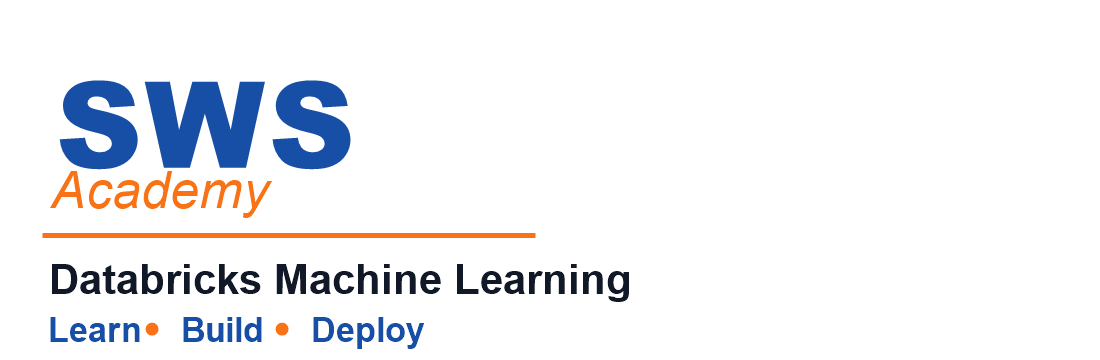

# Scalable Model Training with SparkML and MLflow Tracking

In this notebook, you will learn how to build, train, and manage scalable machine learning workflows using **SparkML** on Databricks.

You will discover how SparkML enables distributed training for classical machine learning algorithms, how to structure pipelines for reproducibility, and how to track experiments and model artifacts using **MLflow** and the **Unity Catalog**. This demonstration uses an Airbnb listings dataset and shows a binary high-price vs. not-high-price classification workflow end-to-end with SparkML + MLflow + Unity Catalog.

> This notebook focuses on **distributed training of classical ML models** (such as Logistic Regression or Random Forest) using SparkML. Deep learning workflows with Ray or PyTorch are covered in another Module.

![MLflow Databricks Integration](https://docs.databricks.com/aws/en/assets/images/mlflow-databricks-integration-ml-fed171835b9207db06e6b4867731a3fe.png)

**Learning Objectives**

By the end of this notebook, you will be able to:

- Explain why **SparkML** is a strong choice for scalable training of classical ML models on Databricks.  
- Load and validate feature tables from the **Databricks Feature Store** to ensure consistent input for distributed training.  
- Prepare datasets for SparkML pipelines, including vector conversion, label casting, and feature validation.  
- Train and evaluate classical ML models (Logistic Regression, Random Forest) using **SparkML** with distributed compute.  
- Track experiments end-to-end with **MLflow**, logging parameters, metrics, predictions, and artifacts.  
- Register and manage models in the **Unity Catalog**, enabling governance, reproducibility, and collaborative workflows.  
- Perform final evaluation using classification metrics, confusion matrices, and visualizations to assess real-world performance.

## REQUIRED - SELECT CLASSIC COMPUTE
Before executing cells in this notebook, please select your classic compute cluster in the lab. Be aware that **Serverless** is enabled by default.

Follow these steps to select the classic compute cluster:
1. Navigate to the top-right of this notebook and click the drop-down menu to select your cluster. By default, the notebook will use **Serverless**.

1. If your cluster is available, select it and continue to the next cell. If the cluster is not shown:
    - In the drop-down, select **More**.
    - In the **Attach to an existing compute resource** pop-up, select the first drop-down. You will see a unique cluster name in that drop-down. Please select that cluster.

**NOTE:** If your cluster has terminated, you might need to restart it in order to select it. To do this:

1. Right-click on **Compute** in the left navigation pane and select *Open in new tab*.

1. Find the triangle icon to the right of your compute cluster name and click it.
1. Wait a few minutes for the cluster to start.
1. Once the cluster is running, complete the steps above to select your cluster.

## Requirements

Please review the following requirements before starting the lesson:

- To run this notebook, you need to use one of the following Databricks runtime(s): `16.4.x-cpu-ml-scala2.12`

##Classroom Setup

Run the following cell to configure your working environment for this course. It will also set your default catalog to **swsacademy** and the schema to your specific schema name shown below using the `USE` statements.
<br></br>


```
USE CATALOG swsacademy;
USE SCHEMA swsacademy.<your unique schema name>;
```

**NOTE:** The `SA` object is only used in SWSAcademy courses and is not available outside of these courses. It will dynamically reference the information needed to run the course.

In [ ]:
%pip install "mlflow>=3.0" "protobuf<5" "pyopenssl>=24.2.1" --upgrade
dbutils.library.restartPython()

In [ ]:
%run ../Includes/Classroom-Setup-02

**Other Conventions:**

Throughout this demo, we'll refer to the object `SA`. This object, provided by SWSAcademy, contains variables such as your username, catalog name, schema name, working directory, and dataset locations. Run the code block below to view these details:

In [ ]:
print(f"Username:          {SA.username}")
print(f"Catalog Name:      {SA.catalog_name}")
print(f"Schema Name:       {SA.schema_name}")
print(f"Working Directory: {SA.paths.working_dir}")

### Pre-Step: Configure MLflow Experiment Path

Before training, we configure the **MLflow experiment location**.  
This ensures that all runs and artifacts are stored in a folder **next to this notebook**.  

In [ ]:
import os
import mlflow

try:
    nb_path = dbutils.entry_point.getDbutils().notebook().getContext().notebookPath().get()
except Exception:
    # Fallback for non-DBX contexts
    nb_path = f"/Users/{SA.username}/Scalable_model_training_with_sparkML"

notebook_dir = os.path.dirname(nb_path)

experiment_name = "Scalable_model_training_with_sparkML"
experiment_path = f"{notebook_dir}/{experiment_name}"

# Create or get the experiment via MLflow
exp = mlflow.get_experiment_by_name(experiment_path)
if exp is None:
    mlflow.create_experiment(experiment_path)

mlflow.set_experiment(experiment_path)
print("Experiment set to:", experiment_path)

## Why Use SparkML for Scalable Model Training on Databricks?

As datasets grow beyond what a single machine can handle, scalable machine learning is critical for enterprise success. While deep learning frameworks like PyTorch and TensorFlow are ideal for custom neural networks, **most production machine learning on structured, tabular data is still driven by classical algorithms**, such as logistic regression, decision trees, and gradient-boosted trees.

Databricks offers **best-in-class support for SparkML**, Apache Spark’s distributed ML library, with tight integration across the data and ML ecosystem.

---

**What Makes SparkML “Integrated and Production-Ready” on Databricks?**

- **Effortless Compute Management**  
  Instantly launch distributed ML jobs on any size cluster, no manual cluster setup, no code changes, and consistent high performance for both development and production.

- **End-to-End MLflow Integration**  
  Every run, parameter, metric, and model version is automatically tracked and visualized through the native [MLflow](https://docs.databricks.com/en/mlflow/index.html) UI.  
  Enable rapid experimentation, reproducibility, model registry, and easy transitions from notebook prototyping to production deployments.

- **Seamless Governance with Unity Catalog**  
  Securely store, share, and audit trained models and results in [Unity Catalog](https://docs.databricks.com/en/data-governance/unity-catalog/index.html), ensuring compliance and discoverability at every stage of the ML lifecycle.

- **Flexible Compute Options**  
  Choose between serverless clusters, autoscaling jobs, or custom compute pools - scaling up or down as project demands change, without vendor lock-in.

- **Cross-Functionality for Data Teams**  
  Engineers, scientists, and analysts work from a single platform, accessing **clean feature tables** through the [Feature Store](https://docs.databricks.com/en/machine-learning/feature-store/index.html) and sharing standardized ML pipelines across teams.

- **Reusable, Versioned Pipelines**  
  SparkML’s pipelines can be saved, versioned, reloaded, and reused across clusters, environments, and stages of model development.

- **Automatic Parallelism & Fault Tolerance**  
  Spark handles partitioning, parallel execution, and redundancy behind the scenes, no complex orchestration or parallel programming required.

---

> **Important: Understanding Parallelism Types  
> SparkML implements data-parallelism:** the dataset is distributed across many executors, each holding an identical model that is trained in parallel before results are aggregated.
>
> **If your workload requires splitting a single large model across devices (model-parallelism),** such as for deep neural networks or LLMs, use specialized frameworks like **TorchDistributor**, **DeepSpeed**, or **Ray + PyTorch**.

---

**Framework Comparison — Choosing the Right Tool**

| Framework                     | Parallelism Type         | Best Suited For                         | Scaling Pattern              |
|-------------------------------|-------------------------|------------------------------------------|------------------------------|
| **SparkML (Connect)**         | Data-parallel           | Classical ML: regression, trees          | Spark executors              |
| **Ray + PyTorch**             | Data + model-parallel   | Custom deep learning, vision/NLP, HPO    | Ray actors/multi-node        |
| **TorchDistributor / DeepSpeed** | Model/tensor-parallel | Large-scale DNNs, LLMs                   | Multi-GPU, sharded model     |
| **xgboost.spark**             | Data-parallel           | Tabular boosting at scale                | Multi-node, tree-optimized   |

---

**Key Takeaway**

For **structured data and classical ML** - where scale, governance, and collaboration are mission-critical, **SparkML provides the most integrated, automated, and production-ready platform on Databricks**.  
**For model- or tensor-parallel deep learning, switch to Ray, TorchDistributor, or DeepSpeed.**

## Part 1: Load Feature Table and Perform Exploratory Data Analysis (EDA)

In this section, you'll load a precomputed **Airbnb feature table** that contains numeric feature vectors derived from property attributes (such as location, room type, and review scores), along with a **binary label** indicating whether a listing is **high-priced** (`is_high_price = 1`) or **not high-priced** (`is_high_price = 0`).  

You will also perform basic exploratory data analysis (EDA) to validate feature consistency and inspect class distribution — a crucial step before training scalable machine learning models.

### 1.1: Load Feature Table

In this step, we load a pre-registered **Airbnb feature table** using the `FeatureEngineeringClient`.  
The table contains:

- **Vectorized numeric features** (`features_array`) derived from Airbnb listing attributes such as location, property type, and review scores  
- A **binary label** `is_high_price`, indicating whether the listing’s price is above the 75th percentile (`1 = high price`, `0 = not high price`)  

We will preview the data, validate feature vector structure, and prepare it for downstream processing.

In [ ]:
from databricks.feature_engineering import FeatureEngineeringClient
import pyspark.sql.functions as F

# Initialize FeatureEngineeringClient
fe = FeatureEngineeringClient()

# Define feature table name (Airbnb)
feature_table_name = f"{SA.catalog_name}.{SA.schema_name}.airbnb_features"

# Load feature table if exists
if spark.catalog.tableExists(feature_table_name):
    features_df = fe.read_table(name=feature_table_name)
    display(features_df)
else:
    print(f"Feature table {feature_table_name} not found.")

### 1.2: Validate Feature Vector and Label Distribution

Before training the model, it's important to validate the quality and consistency of the input data. In this step, we perform two key checks:

- **Feature vector consistency**: Ensure that all `features_array` entries have the same length, which is required for SparkML pipeline compatibility.  
- **Label distribution**: Examine the balance of the binary `is_high_price` column to detect potential class imbalance, which can affect model performance.

We use simple aggregations to display the distribution of feature vector lengths and label counts.

In [ ]:
# Check feature vector length (should be consistent across all records)
vec_stats = features_df.selectExpr("size(features_array) as vec_length") \
                       .groupBy("vec_length").count()
display(vec_stats)

# Check label distribution (0 = low/mid price, 1 = high price)
label_dist = features_df.groupBy("is_high_price").count()
display(label_dist)

## Part 2: Train/Test Split and Data Preparation

Before training a model with **SparkML**, we need to prepare the dataset in a format compatible with Spark’s ML pipeline APIs. This step ensures both correctness and scalability across the cluster.

In this part, we will:
- **Split** the dataset into training and test sets for evaluation.  
- **Convert** `features_array` into a SparkML-compatible `Vector` format.  
- **Cast** the `is_high_price` column to `double`, as required by most SparkML estimators.  
- **Validate** the integrity of the transformed dataset by checking feature vector lengths and label distributions.  

Proper data preparation is essential to ensure that the training pipeline runs efficiently and produces reliable results.

### 2.1: Train/Test Split

To evaluate model performance on unseen data, we split the dataset into training and test sets. 

In this step:
- We use an **80/20 split** ratio, which is a common default for binary classification tasks.
- A fixed **random seed** ensures reproducibility of the split across runs.
- We optionally display the number of rows in each set to verify the distribution.

This separation ensures that the model is trained on one portion of the data and evaluated on another, helping to prevent overfitting.

In [ ]:
from pyspark.sql import functions as F

# Set split ratio and random seed
TRAIN_RATIO = 0.8
SEED = 42

# Split the dataset
train_df, test_df = features_df.randomSplit([TRAIN_RATIO, 1 - TRAIN_RATIO], seed=SEED)

# Optional: Display sample sizes
print(f"Train rows: {train_df.count()} | Test rows: {test_df.count()}")

### 2.2: Bring Features & Label Together for Train/Test

In this step, we retrieve features from the **Airbnb Feature Store table** using **`FeatureLookup`** and join them with our training and test splits.

The table contains:
- `features_array`: Numeric feature vectors derived from Airbnb listing attributes  
- `price`: Original listing price  
- `is_high_price`: Binary label indicating whether the listing is above the 75th percentile in price  

By performing this lookup and join, we ensure that our model training data is consistent with production features, supporting **feature reuse**, **governance**, and reproducibility across **training** and **inference** workflows.

In [ ]:
from databricks.feature_engineering import FeatureEngineeringClient, FeatureLookup

# Initialize FeatureEngineeringClient
fe = FeatureEngineeringClient()

# Define FeatureLookups for Airbnb dataset
airbnb_lookup = FeatureLookup(
    table_name=f"{SA.catalog_name}.{SA.schema_name}.airbnb_features",
    lookup_key="id",
    feature_names=["features_array", "price", "is_high_price"]
)

# Load feature table (Airbnb)
airbnb_features = fe.read_table(name=airbnb_lookup.table_name).alias("airbnb")

# Create training preview (example join on 'id')
train_preview_df = (
    train_df.alias("base")
    .join(airbnb_features, on="id", how="left")
    .select(
        "base.id",              # Primary key
        "base.is_high_price",   # Target column
        "airbnb.features_array",# Vectorized numeric features
        "airbnb.price"          # Additional reference column
    )
)

# Create test preview similarly
test_preview_df = (
    test_df.alias("base")
    .join(airbnb_features, on="id", how="left")
    .select(
        "base.id",
        "base.is_high_price",
        "airbnb.features_array",
        "airbnb.price"
    )
)

# Preview the cleaned DataFrame
display(train_preview_df.limit(10))

### 2.3: Convert Features to SparkML Format

To train models using **SparkML**, the dataset must follow a specific schema:

- A column named **`features`** of type `VectorUDT`, which holds the feature vectors.  
- A column named **`label`** of type `double`, representing the target variable (`is_high_price`).  

In this step, we:
- Convert the `features_array` column (of type `Array[Double]`) into a `Vector` using the built-in `array_to_vector()` function.  
- Cast the `is_high_price` column to `double` to meet estimator requirements.  
- Select the relevant columns (`id`, `features`, `price`, and `label`) for training and evaluation.  

This transformation prepares both the training and test sets for use in SparkML pipelines.

In [ ]:
from pyspark.ml.functions import array_to_vector
from pyspark.sql.functions import monotonically_increasing_id
import pyspark.sql.functions as F

def cast_for_sparkml(df):
    # Add 'id' if missing
    if 'id' not in df.columns:
        df = df.withColumn("id", monotonically_increasing_id())

    return (
        df.withColumn("features", array_to_vector("features_array"))
          .withColumn("label", F.col("is_high_price").cast("double"))
          .select("id", "features", "price", "label")
    )

# Apply to lookup-enriched DataFrames
train_ml = cast_for_sparkml(train_preview_df)
test_ml = cast_for_sparkml(test_preview_df)

# Preview transformed training set
display(train_ml)

#### (Optional) Cache Transformed Data

To improve performance in downstream operations, we optionally **cache** the transformed training and test datasets.

Since these DataFrames will be accessed multiple times during model training and evaluation, caching them in memory avoids redundant computation and speeds up execution.

In [ ]:
# Cache datasets for repeated access
train_ml.cache()
test_ml.cache()

### 2.4: Validate Train/Test Label Distribution

To detect potential class imbalance issues, we verify the distribution of labels in both the training and test sets.  
This helps ensure that the split preserved the original class proportions and that the model will be trained on representative data.

In [ ]:
def show_label_distribution(df, label="label", name="Dataset"):
    print(f"\n{name} Label Distribution:")
    display(df.groupBy(label).count().orderBy(F.desc("count")))

# Display label distribution for Train and Test splits
show_label_distribution(train_ml, name="Train")
show_label_distribution(test_ml, name="Test")

### 2.5: Validate Feature Vector Consistency and Preview

Before training, we need to ensure that the `features_array` column is properly structured for SparkML:

- **Consistency check:** All feature vectors must have the same length.  
- **Preview & visualization:** Sampling a small batch of vectors helps confirm dimensionality, inspect typical values, and detect anomalies such as empty or unusually large vectors.

The plots provide a quick exploratory view:
- First few feature dimensions across 50 rows (line plot)  
- Distribution of vector magnitudes (histogram of L2 norms)  

These checks confirm feature readiness and highlight potential preprocessing needs.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyspark.sql.functions as F

# Quick length check using Spark (Airbnb features_array)
vec_stats = (
    train_preview_df
    .select(F.size("features_array").alias("vector_length"))
    .groupBy()
    .agg(
        F.min("vector_length").alias("min_len"),
        F.max("vector_length").alias("max_len")
    )
    .collect()[0]
)
print(f"Train feature array min/max length: {vec_stats['min_len']} / {vec_stats['max_len']}")

# Sample a small batch for visualization from SparkML-ready DF
sample_pdf = train_ml.select("features").limit(200).toPandas()
arrs = [np.array(v.toArray()) for v in sample_pdf["features"]]
X = np.vstack(arrs) if arrs else np.empty((0, 0))

print(f"Sample size: {X.shape[0]} | Vector length: {X.shape[1] if X.size else 0}")

if X.size:
    # Plot first few dimensions across rows
    dims_to_show = min(3, X.shape[1])
    plt.figure(figsize=(7, 4))
    for d in range(dims_to_show):
        plt.plot(X[:50, d], alpha=0.7, label=f"feat[{d}]")
    plt.title("Airbnb: preview of first feature dimensions (first 50 rows)")
    plt.xlabel("Row index")
    plt.ylabel("Value")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Plot L2 norm distribution
    norms = np.linalg.norm(X, axis=1)
    plt.figure(figsize=(6, 4))
    plt.hist(norms, bins=20)
    plt.title("Airbnb: distribution of feature vector L2 norms")
    plt.xlabel("L2 norm")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()
else:
    print("No vectors available to visualize.")

#### Interpretation of Feature Vector Preview

The plots above provide a quick exploratory check of the **feature vectors**:

- **Consistency:** All sampled vectors have equal length, confirming schema alignment for SparkML pipelines.  
- **Feature behavior:** The line plot of the first few feature dimensions across sample rows shows smooth variation, with values centered near zero and no visible anomalies.  
- **Vector magnitudes:** The histogram of L2 norms indicates most vectors fall within a compact range, with a few larger values that could correspond to distinct property patterns.  

These checks confirm that the features are well-structured and ready for scalable model training.

## Part 3: Train a SparkML Model and Track with MLflow

With the data prepared and formatted for SparkML, we are now ready to train a machine learning model.  
In this section, you'll:

- Build a **SparkML classification model** using either `LogisticRegression` or `RandomForestClassifier`.
- **Track the full training pipeline** using [MLflow](https://docs.databricks.com/en/mlflow/index.html), including parameters, metrics, predictions, and model artifacts.
- **Log and register the trained model** in Unity Catalog for reproducibility, governance, and potential deployment.

### 3.1: Import Required Libraries and Initialize MLflow

We begin by importing SparkML estimators and the MLflow tracking library.  
We also end any previously active MLflow run to avoid tracking conflicts.

In [ ]:
# Import MLflow and SparkML modules
import mlflow
import mlflow.spark
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Optional: End any active MLflow runs
mlflow.end_run()

### 3.2: Choose and Configure the Model

You can choose between two classical ML models:
- `LogisticRegression`: For linear, interpretable classification tasks
- `RandomForestClassifier`: For ensemble-based nonlinear models

We initialize the selected model with basic hyperparameters and set the MLflow experiment path to track all runs under the current user’s workspace.

In [ ]:
# Define model type: Choose from ["LogisticRegression", "RandomForest"]
MODEL_TYPE = "LogisticRegression"  # Or change to "RandomForest"

Once you have selected the `MODEL_TYPE`, the next step is to **initialize the corresponding SparkML estimator**.  
This ensures that the training pipeline uses the correct algorithm with predefined hyperparameters:

- For **Logistic Regression**, we specify parameters such as maximum iterations, regularization strength, and elastic net mixing.  
- For **Random Forest**, we define parameters such as the number of trees, maximum depth, and random seed for reproducibility.  

These configurations establish the model’s baseline behavior, which can later be tuned through hyperparameter optimization.

In [ ]:
# Initialize model
if MODEL_TYPE == "LogisticRegression":
    sparkML_model = LogisticRegression(
        featuresCol="features", 
        labelCol="label", 
        maxIter=50,
        regParam=0.1, 
        elasticNetParam=0.0,
        family="binomial"  # Updated for binary classification
    )
elif MODEL_TYPE == "RandomForest":
    sparkML_model = RandomForestClassifier(
        featuresCol="features", 
        labelCol="label", 
        numTrees=50,
        maxDepth=5,
        seed=42
    )
else:
    raise ValueError("Invalid MODEL_TYPE specified")

### 3.3 - Train, Evaluate, Log, and Register the Model

In this sequence, we:

1. **Start an MLflow run** and log model metadata such as parameters and type.
2. **Train the selected model** using the prepared `train_ml` dataset.
3. **Run predictions** on the test set and cache results for evaluation.
4. **Evaluate model performance** using:
   - Accuracy
   - F1 Score
   - Confusion Matrix
5. **Log metrics** to MLflow for future comparison.
6. **Log the trained model** to MLflow along with:
   - An inferred model signature
   - A sample input example using the original `features_array`
7. **Register the model** in Unity Catalog using `MlflowClient()` and assign version tags and aliases.

This workflow demonstrates how to track, audit, and compare model runs in a scalable team environment.

In [ ]:
from mlflow.models.signature import infer_signature
import mlflow
import mlflow.spark
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.sql import functions as F
from pyspark.ml.functions import vector_to_array

# MLflow Run/Tracking 
with mlflow.start_run(run_name=f"{MODEL_TYPE} Baseline (Airbnb)") as run:
    mlflow.log_param("model_type", MODEL_TYPE)
    # Log hyperparameters
    if MODEL_TYPE == "LogisticRegression":
        mlflow.log_params({
            "maxIter": sparkML_model.getMaxIter(),
            "regParam": sparkML_model.getRegParam(),
            "elasticNetParam": sparkML_model.getElasticNetParam(),
            "family": sparkML_model.getFamily(),
        })
    else:
        mlflow.log_params({
            "numTrees": sparkML_model.getNumTrees(),
            "maxDepth": sparkML_model.getMaxDepth(),
            "seed": sparkML_model.getSeed(),
        })
        
    # Train Model
    fitted_model = sparkML_model.fit(train_ml)

    # Predict/Test Output
    pred_df = fitted_model.transform(test_ml).cache()
    display(pred_df.select("label", "prediction", "probability").limit(10))  # View results

    # Evaluate: Accuracy, F1, log metrics
    evaluator_acc = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
    evaluator_f1  = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")
    metrics = {
        "accuracy": evaluator_acc.evaluate(pred_df),
        "f1_score":  evaluator_f1.evaluate(pred_df)
    }
    print(f"Test accuracy: {metrics['accuracy']:.3f}")
    print(f"Test F1 score: {metrics['f1_score']:.3f}")
    mlflow.log_metrics(metrics)

    # Confusion Matrix
    cm_df = pred_df.groupBy("label", "prediction").count().orderBy("label", "prediction")
    print("Confusion Matrix:")
    display(cm_df)

    # Input example & signature
    # Use array-based example (avoid DenseVector serialization pitfalls)
    input_example_df = (
        test_preview_df
        .select(F.col("features_array").alias("features"),
                F.col("is_high_price").alias("label"))
        .limit(5)
        .toPandas()
    )

    # Prefer vector-based signature; fall back to array form if needed
    try:
        sig_input_df  = train_ml.select("features", "label").limit(50).toPandas()
        sig_output_df = fitted_model.transform(train_ml.limit(50)).select("prediction").toPandas()
        signature = infer_signature(sig_input_df, sig_output_df)
    except Exception as e:
        print("Vector-based signature failed, falling back to array form:", e)
        sig_input_df  = train_ml.select(vector_to_array("features").alias("features"), "label").limit(50).toPandas()
        sig_output_df = fitted_model.transform(train_ml.limit(50)).select("prediction").toPandas()
        signature = infer_signature(sig_input_df, sig_output_df)

    # Log model to MLflow
    mlflow.spark.log_model(
        fitted_model,
        "sparkml_model",
        input_example=input_example_df,
        signature=signature
    )
    print("Model logged to MLflow run:", run.info.run_id)

    # Optionally, register (otherwise do this in MLflow UI):
    model_name = "Airbnb_SparkML_Model"
    result = mlflow.register_model(f"runs:/{run.info.run_id}/sparkml_model", model_name)
    client = mlflow.tracking.MlflowClient()
    client.set_registered_model_alias(name=model_name, alias="baseline", version=result.version)
    client.set_model_version_tag(name=model_name, version=result.version, key="accuracy", value=str(metrics["accuracy"]))
    client.update_model_version(
        name=model_name,
        version=result.version,
        description=(
            f"Baseline SparkML model (v{result.version}) on Airbnb numeric features; "
            f"label = is_high_price; logged with MLflow and registered in Unity Catalog."
        )
    )

In this step, we:
- Trained a baseline **SparkML classification model**
- Logged all relevant artifacts and metrics to **MLflow**
- Registered the model in **Unity Catalog** with versioning and metadata
- Enabled reproducible, scalable, and collaborative model experimentation

## Part 4: Final Evaluation on Test Set

Now that the model has been trained and logged, we will conduct a detailed evaluation on the **test set** to assess real-world performance.

This includes:
- Computing standard classification metrics (accuracy, F1 score)
- Generating a full classification report using `sklearn`
- Visualizing the **confusion matrix**
- Evaluating advanced metrics like **AUC PR**

In [ ]:
# Import libraries for evaluation and visualization
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert Spark DataFrame to Pandas for sklearn evaluation
pdf = pred_df.select("label", "prediction").toPandas()

# Ensure consistent label order
labels = sorted(pdf["label"].unique())
print("Labels in test set:", labels)

# Basic accuracy
acc = (pdf["label"] == pdf["prediction"]).mean()
print(f"\nTest Accuracy: {acc:.3f}")

# Classification report
print("\nClassification Report:")
print(classification_report(pdf["label"], pdf["prediction"], digits=3))

# Confusion matrix
cm = confusion_matrix(pdf["label"], pdf["prediction"], labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

print("\nConfusion Matrix (rows = true labels, cols = predicted labels):")
display(cm_df)

# Heatmap plot
plt.figure(figsize=(7, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

### 4.2: Evaluate with Binary (Multiclass-Compatible) Metrics

Although this is a **binary classification** problem, we can still use the `MulticlassClassificationEvaluator` in SparkML to compute metrics such as **F1 score**, **weighted precision**, and **weighted recall**.  
These metrics provide a comprehensive view of model performance, accounting for any potential class imbalance between high-priced and non–high-priced listings.

In [ ]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# F1 Score
f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="f1"
)
f1_score = f1_evaluator.evaluate(pred_df)
print(f"Multiclass F1 Score: {f1_score:.3f}")

# Weighted Precision
precision_evaluator = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="weightedPrecision"
)
weighted_precision = precision_evaluator.evaluate(pred_df)
print(f"Weighted Precision: {weighted_precision:.3f}")

# Weighted Recall
recall_evaluator = MulticlassClassificationEvaluator(
    labelCol="label", predictionCol="prediction", metricName="weightedRecall"
)
weighted_recall = recall_evaluator.evaluate(pred_df)
print(f"Weighted Recall: {weighted_recall:.3f}")

## Conclusion

In this notebook, you demonstrated how to scale classical machine learning workflows on Databricks using **SparkML**.  
You prepared and validated features, trained distributed models, and evaluated their performance on structured data.  
Through **MLflow** integration, you tracked experiments and registered models in **Unity Catalog**, ensuring reproducibility and team collaboration.  
This workflow highlights how enterprise teams can operationalize scalable ML pipelines with governance, efficiency, and consistency across environments.

<div style="border-top: 1px solid #E5E7EB; margin-top: 32px; padding: 12px 0; color: #4B5563; font-size: 13px; font-family: Arial, Helvetica, sans-serif; line-height: 1.5;">
  <div><strong>SWS Academy</strong> &nbsp;|&nbsp; Databricks AI &amp; Machine Learning Course</div>
  <div>&copy; 2026 SWS Academy. All rights reserved. Unauthorized reproduction or distribution is prohibited.</div>
</div>